# Olist: Barplots y Pie Charts
### Ejercicios de visualización con Pandas y Matplotlib

En esta nota trabajamos con el dataset de Olist para practicar gráficas de barras (barplots) y gráficas de pastel (pie charts).

Antes de cada gráfica seguimos el mismo orden:

1. **Primero la pregunta**: ¿qué queremos saber?
2. **Después los datos**: ¿qué variables necesitamos y qué operación hacemos sobre ellas?
3. **Finalmente, la gráfica**: ¿qué tipo de gráfica representa mejor el resultado?

> Los CSV de Olist se cargan desde la carpeta `datos_olist_reales`. Si no la encuentra, abre esta nota desde `examen_olist` o ajusta la variable `carpeta`.

## Preparación: librerías y datos

In [33]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Los CSV originales de Olist están junto a esta nota.
opciones = [
    Path.cwd() / "datos_olist_reales",
    Path.cwd() / "estudio_pandas" / "examen_olist" / "datos_olist_reales",
    Path.cwd().parent / "datos_olist_reales",
]
carpeta = next((p for p in opciones if (p / "olist_orders_dataset.csv").is_file()), None)
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro datos_olist_reales. Abre esta nota desde examen_olist "
        "o ajusta la variable carpeta a su ubicación."
    )

orders = pd.read_csv(carpeta / "olist_orders_dataset.csv")
customers = pd.read_csv(carpeta / "olist_customers_dataset.csv")
order_items = pd.read_csv(carpeta / "olist_order_items_dataset.csv")
products = pd.read_csv(carpeta / "olist_products_dataset.csv")
sellers = pd.read_csv(carpeta / "olist_sellers_dataset.csv")
order_payments = pd.read_csv(carpeta / "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(carpeta / "olist_order_reviews_dataset.csv")
translation = pd.read_csv(carpeta / "product_category_name_translation.csv")

In [34]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [35]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [36]:
order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### Colores que usaremos en las gráficas

Definimos los colores una sola vez para que todas las gráficas se vean parecidas.
El gris se reserva para la categoría `"Otros"` de los pie charts.

In [37]:
color_barras = "#2a78d6"
color_barras_secundario = "#eb6834"
colores_pie_con_otros = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#c3c2b7"]
colores_metodos_pago = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

---
## Ejercicio 1: Categorías de productos

**Pregunta:** ¿Qué categorías tienen mayor presencia en el catálogo de Olist?



In [38]:
cantidad_productos_por_categoria = products["product_category_name"].value_counts()
cantidad_productos_por_categoria = cantidad_productos_por_categoria.sort_values(ascending=False)

print("Número de categorías:", len(cantidad_productos_por_categoria))
cantidad_productos_por_categoria

Número de categorías: 73


product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 73, dtype: int64

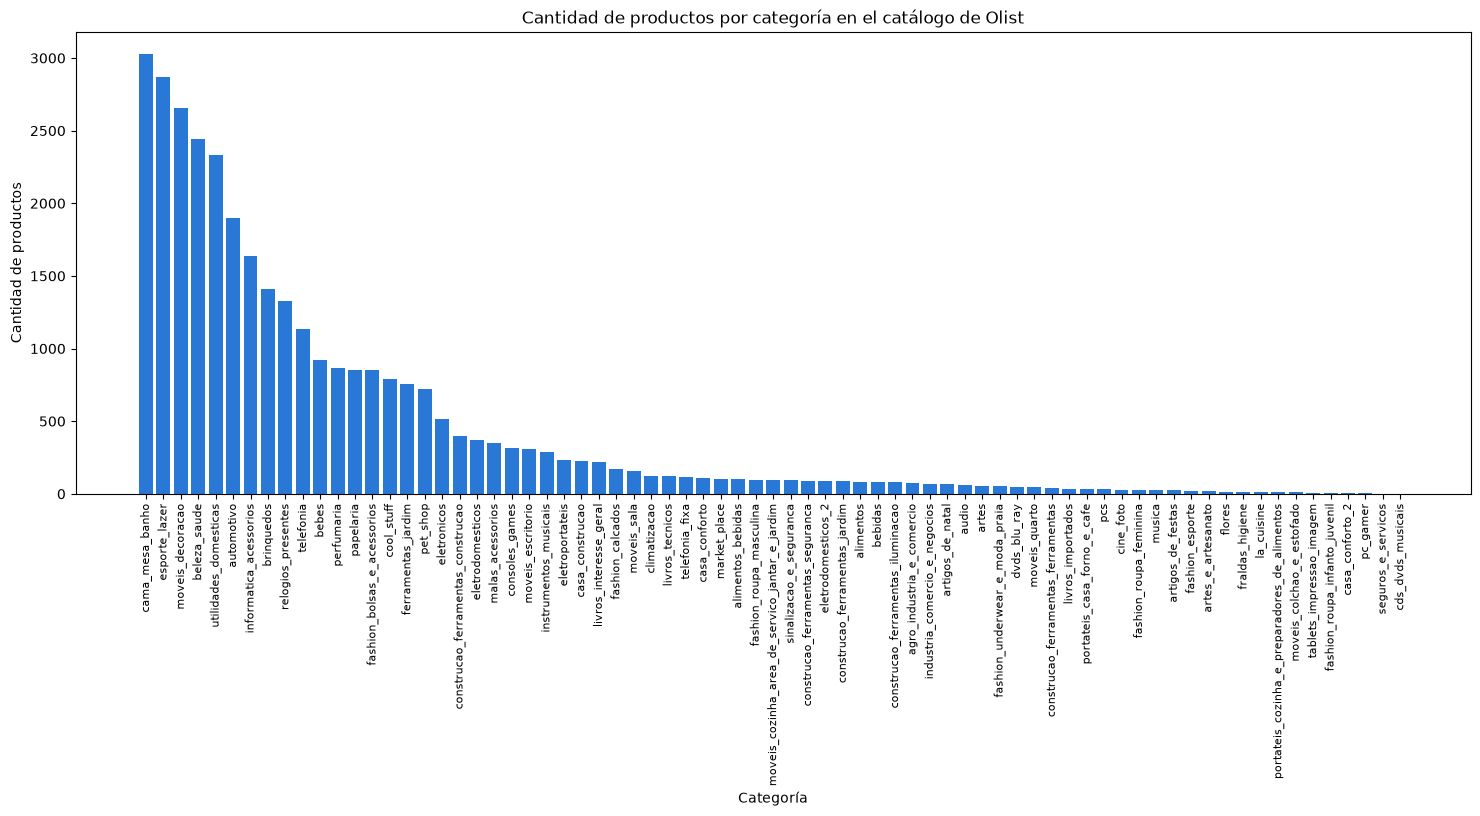

In [39]:
fig, ax = plt.subplots(figsize=(18, 6))

ax.bar(cantidad_productos_por_categoria.index, cantidad_productos_por_categoria.values, color=color_barras)

ax.set_title("Cantidad de productos por categoría en el catálogo de Olist")
ax.set_xlabel("Categoría")
ax.set_ylabel("Cantidad de productos")
plt.xticks(rotation=90, fontsize=8)

plt.show()

---
## Ejercicio 2: Las 10 categorías principales

**Pregunta:** ¿Cuáles son las categorías que tienen mayor presencia en el catálogo?


- **Gráfica:** barras horizontales, porque los nombres de las categorías son largos y se leen mejor en el eje vertical.

In [40]:
top_10_categorias = cantidad_productos_por_categoria.head(10)
top_10_categorias

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

En una gráfica de barras horizontales matplotlib dibuja el primer valor abajo. Usamos `ax.invert_yaxis()` para que la categoría con más productos quede arriba.

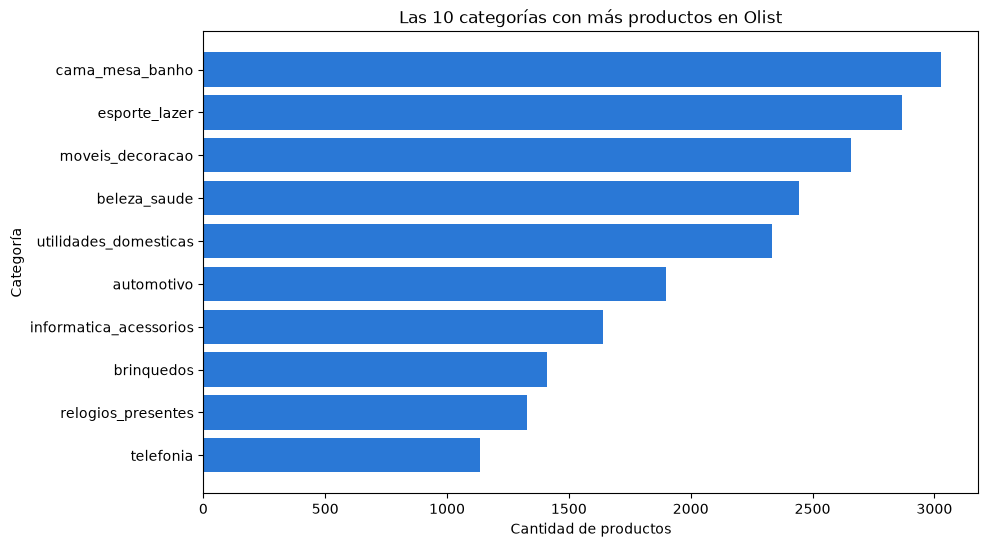

In [41]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(top_10_categorias.index, top_10_categorias.values, color=color_barras)
ax.invert_yaxis()

ax.set_title("Las 10 categorías con más productos en Olist")
ax.set_xlabel("Cantidad de productos")
ax.set_ylabel("Categoría")

plt.show()

---
## Ejercicio 3: Distribución de productos

**Pregunta:** ¿Qué proporción del catálogo está concentrada en las principales categorías?
- **Gráfica:** pie chart, porque queremos ver qué parte del total representa cada grupo.

In [42]:
top_5_categorias = cantidad_productos_por_categoria.head(5)
cantidad_productos_otras_categorias = cantidad_productos_por_categoria.iloc[5:].sum()

distribucion_productos = top_5_categorias.copy()
distribucion_productos["Otros"] = cantidad_productos_otras_categorias

distribucion_productos

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
Otros                    19009
Name: count, dtype: int64

In [43]:
porcentaje_productos_top_5 = top_5_categorias.sum() / cantidad_productos_por_categoria.sum() * 100
print("Porcentaje del catálogo en las 5 categorías principales:", round(porcentaje_productos_top_5, 1), "%")

Porcentaje del catálogo en las 5 categorías principales: 41.2 %


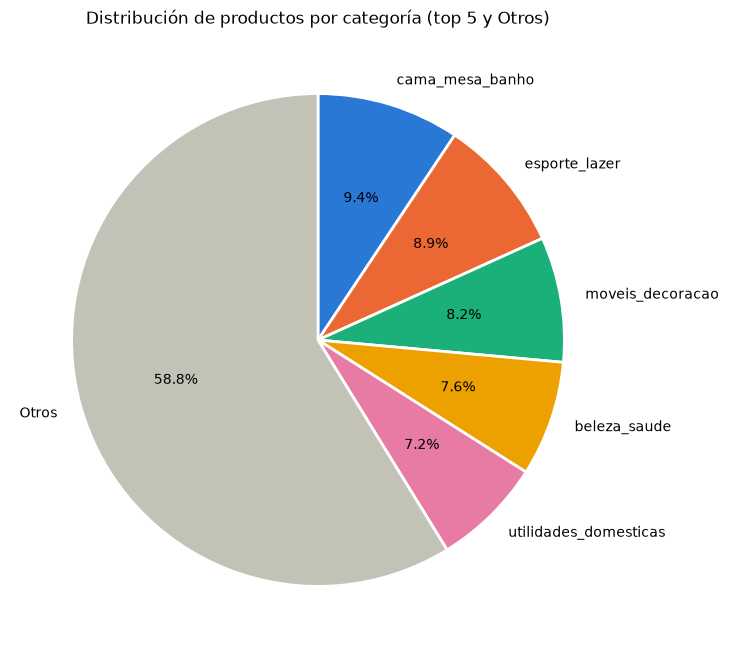

In [44]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    distribucion_productos.values,
    labels=distribucion_productos.index,
    autopct="%1.1f%%",
    colors=colores_pie_con_otros,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

ax.set_title("Distribución de productos por categoría (top 5 y Otros)")

plt.show()

---
## Ejercicio 4: Clientes por estado

**Pregunta:** ¿Qué estados concentran la mayor cantidad de clientes?


In [45]:
print("Registros en la tabla de clientes:", len(customers))

clientes_unicos = customers.drop_duplicates(subset="customer_unique_id")
print("Clientes únicos:", len(clientes_unicos))

Registros en la tabla de clientes: 99441
Clientes únicos: 96096


In [46]:
cantidad_clientes_por_estado = clientes_unicos["customer_state"].value_counts()
cantidad_clientes_por_estado = cantidad_clientes_por_estado.sort_values(ascending=False)

print("Número de estados:", len(cantidad_clientes_por_estado))
cantidad_clientes_por_estado

Número de estados: 27


customer_state
SP    40295
RJ    12377
MG    11255
RS     5277
PR     4882
SC     3529
BA     3276
DF     2073
ES     1963
GO     1951
PE     1604
CE     1311
PA      949
MT      875
MA      725
MS      693
PB      519
PI      482
RN      474
AL      401
SE      341
TO      273
RO      239
AM      143
AC       77
AP       67
RR       45
Name: count, dtype: int64

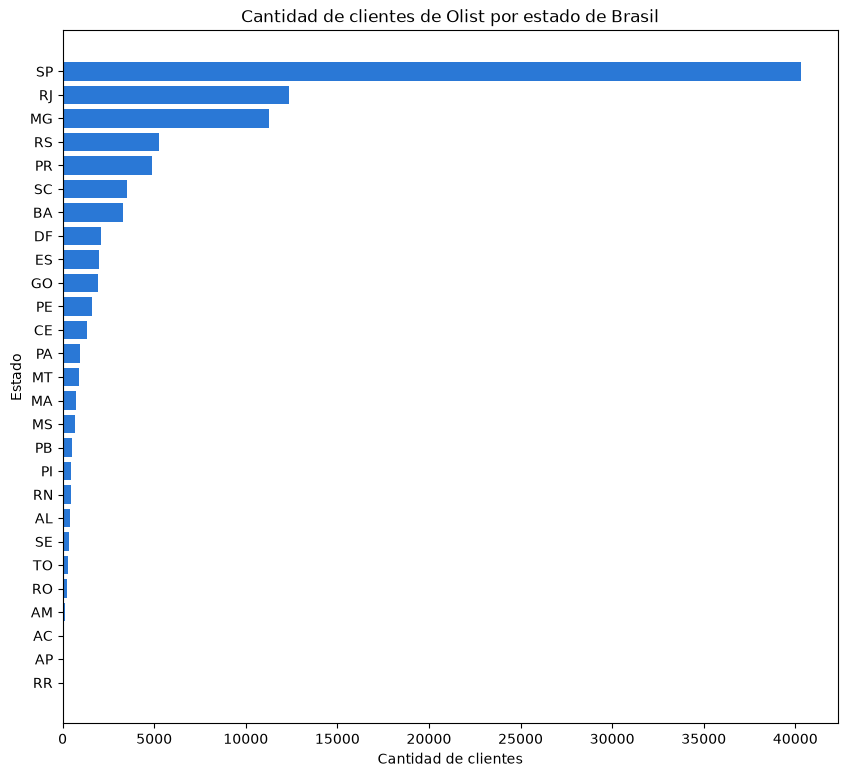

In [47]:
fig, ax = plt.subplots(figsize=(10, 9))

ax.barh(cantidad_clientes_por_estado.index, cantidad_clientes_por_estado.values, color=color_barras)
ax.invert_yaxis()

ax.set_title("Cantidad de clientes de Olist por estado de Brasil")
ax.set_xlabel("Cantidad de clientes")
ax.set_ylabel("Estado")

plt.show()

---
## Ejercicio 5: Estados principales

**Pregunta:** ¿Qué tan concentrada está la base de clientes geográficamente?



In [48]:
top_5_estados = cantidad_clientes_por_estado.head(5)
cantidad_clientes_otros_estados = cantidad_clientes_por_estado.iloc[5:].sum()

distribucion_clientes = top_5_estados.copy()
distribucion_clientes["Otros"] = cantidad_clientes_otros_estados

distribucion_clientes

customer_state
SP       40295
RJ       12377
MG       11255
RS        5277
PR        4882
Otros    22010
Name: count, dtype: int64

In [49]:
porcentaje_clientes_top_5 = top_5_estados.sum() / cantidad_clientes_por_estado.sum() * 100
print("Porcentaje de clientes en los 5 estados principales:", round(porcentaje_clientes_top_5, 1), "%")

Porcentaje de clientes en los 5 estados principales: 77.1 %


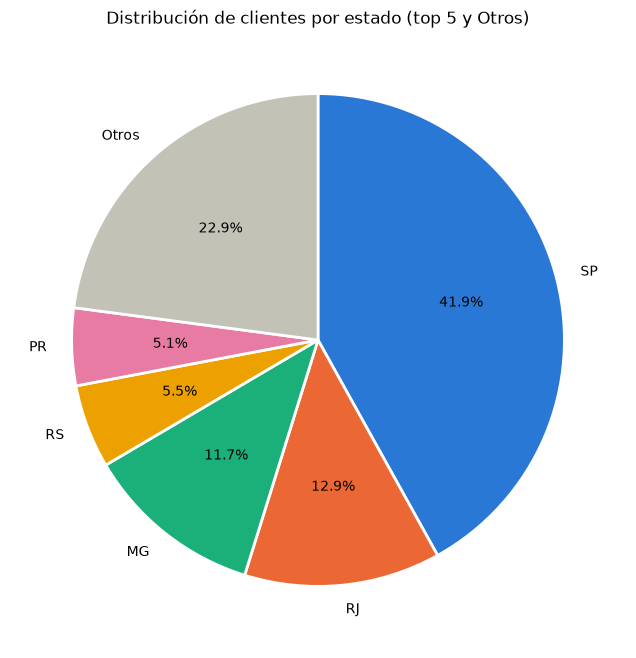

In [50]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    distribucion_clientes.values,
    labels=distribucion_clientes.index,
    autopct="%1.1f%%",
    colors=colores_pie_con_otros,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

ax.set_title("Distribución de clientes por estado (top 5 y Otros)")

plt.show()

---
## Ejercicio 6: Métodos de pago

**Pregunta:** ¿Cuál es el método de pago más utilizado?


In [51]:
cantidad_pagos_por_metodo = order_payments["payment_type"].value_counts()
cantidad_pagos_por_metodo = cantidad_pagos_por_metodo.sort_values(ascending=False)

cantidad_pagos_por_metodo

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

### Gráfica de barras

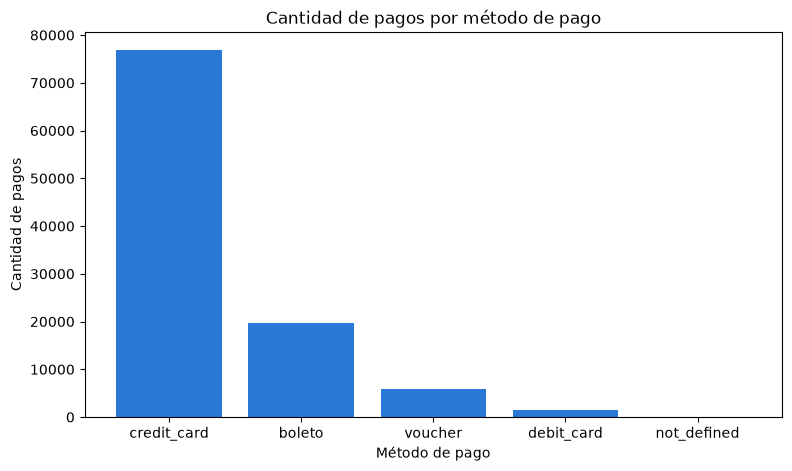

In [52]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(cantidad_pagos_por_metodo.index, cantidad_pagos_por_metodo.values, color=color_barras)

ax.set_title("Cantidad de pagos por método de pago")
ax.set_xlabel("Método de pago")
ax.set_ylabel("Cantidad de pagos")

plt.show()

### Pie chart

Algunos métodos de pago tienen porcentajes muy pequeños y sus textos se encimarían. Por eso hacemos una función que solo muestra el porcentaje cuando es de 1% o más, colocamos los porcentajes afuera del pastel con `pctdistance` y ponemos los nombres de los métodos en una leyenda.

In [53]:
def mostrar_porcentaje_si_es_visible(porcentaje):
    if porcentaje < 1:
        return ""
    return f"{porcentaje:.1f}%"

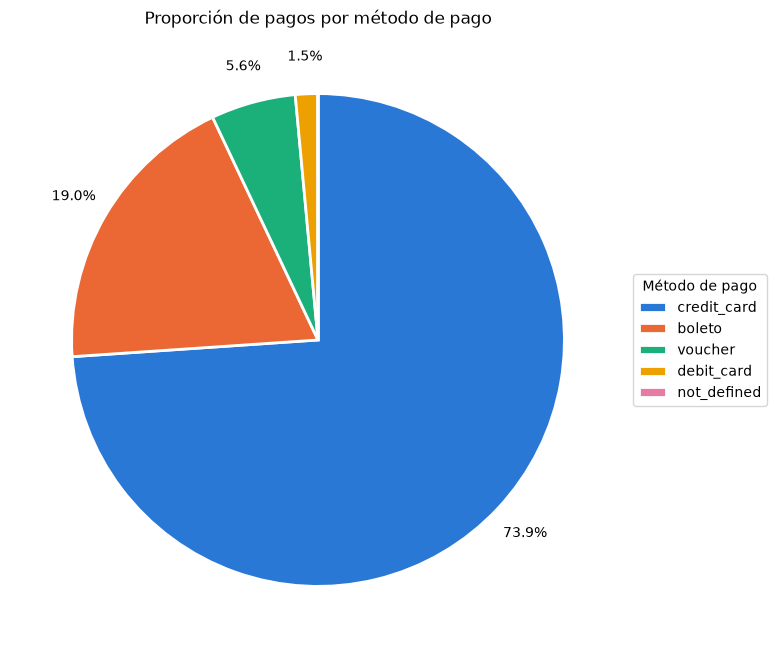

In [54]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    cantidad_pagos_por_metodo.values,
    autopct=mostrar_porcentaje_si_es_visible,
    pctdistance=1.15,
    colors=colores_metodos_pago,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

ax.legend(cantidad_pagos_por_metodo.index, title="Método de pago", loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Proporción de pagos por método de pago")

plt.show()



### Reflexión

**¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?**
La gráfica de barras. Todas las barras empiezan en cero y comparamos alturas, así es fácil ver cuánto más grande es un método que otro.

**¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?**
El pie chart, porque muestra cada método como una parte del total (100%) y deja muy claro que la tarjeta de crédito ocupa casi tres cuartas partes de todos los pagos.

---
## Ejercicio 7: Número de cuotas

**Pregunta:** ¿Qué número de cuotas es el más frecuente?



In [55]:
cantidad_pagos_por_cuotas = order_payments.groupby("payment_installments")["order_id"].count()
cantidad_pagos_por_cuotas

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: order_id, dtype: int64

In [56]:
numero_cuotas_mas_frecuente = cantidad_pagos_por_cuotas.idxmax()
print("Número de cuotas más frecuente:", numero_cuotas_mas_frecuente)
print("Pagos con ese número de cuotas:", cantidad_pagos_por_cuotas.max())

Número de cuotas más frecuente: 1
Pagos con ese número de cuotas: 52546


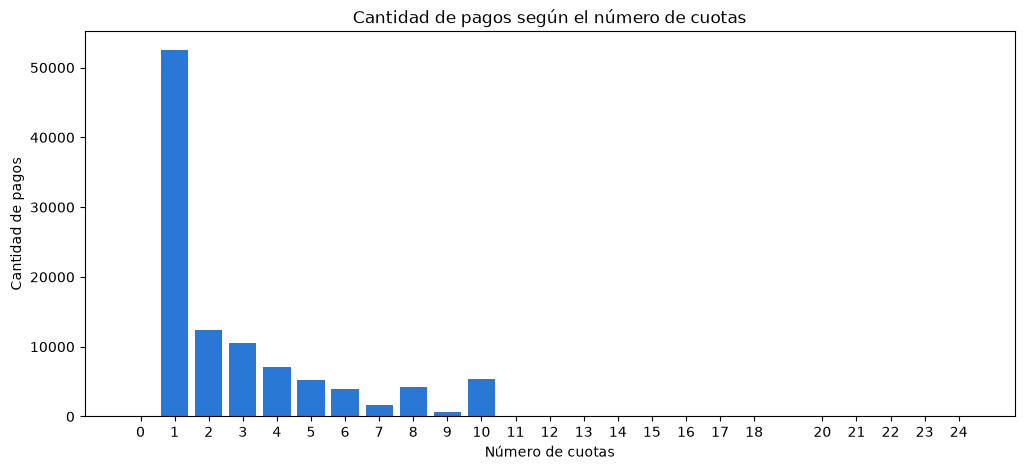

In [57]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(cantidad_pagos_por_cuotas.index, cantidad_pagos_por_cuotas.values, color=color_barras)

ax.set_title("Cantidad de pagos según el número de cuotas")
ax.set_xlabel("Número de cuotas")
ax.set_ylabel("Cantidad de pagos")
plt.xticks(cantidad_pagos_por_cuotas.index)

plt.show()

### Reto: solo de 1 a 10 cuotas

In [58]:
pagos_de_1_a_10_cuotas = order_payments[(order_payments["payment_installments"] >= 1) & (order_payments["payment_installments"] <= 10)]

cantidad_pagos_de_1_a_10_cuotas = pagos_de_1_a_10_cuotas.groupby("payment_installments")["order_id"].count()
cantidad_pagos_de_1_a_10_cuotas

payment_installments
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
Name: order_id, dtype: int64

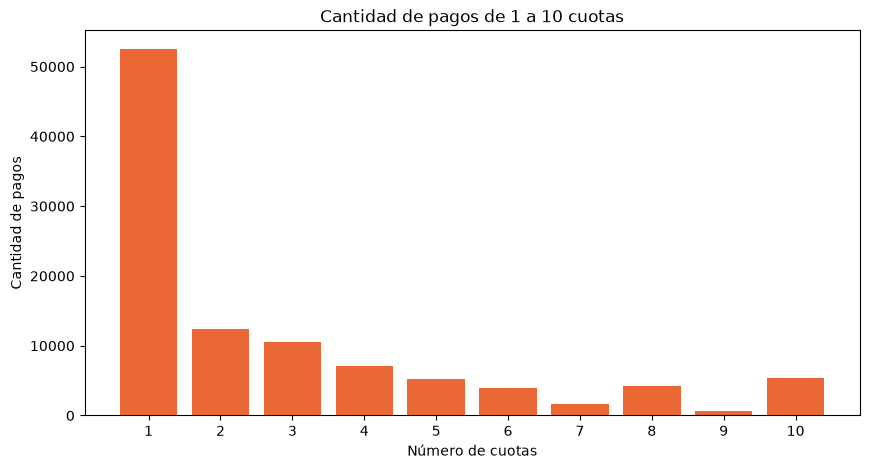

In [59]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(cantidad_pagos_de_1_a_10_cuotas.index, cantidad_pagos_de_1_a_10_cuotas.values, color=color_barras_secundario)

ax.set_title("Cantidad de pagos de 1 a 10 cuotas")
ax.set_xlabel("Número de cuotas")
ax.set_ylabel("Cantidad de pagos")
plt.xticks(range(1, 11))

plt.show()

---
## Ejercicio 8: Comparando visualizaciones

**Pregunta:** ¿Cuál utilizarías en un reporte para comparar los métodos de pago? ¿Y cuál para enfatizar la proporción de cada método?

- **Variable:** `payment_type`.
- **Operación:** usamos exactamente el mismo conteo del ejercicio 6 (`cantidad_pagos_por_metodo`), así las dos gráficas representan los mismos datos.
- **Gráfica:** barras y pie chart, una junto a la otra. Cada método tiene el mismo color en las dos gráficas.

In [60]:
cantidad_pagos_por_metodo

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

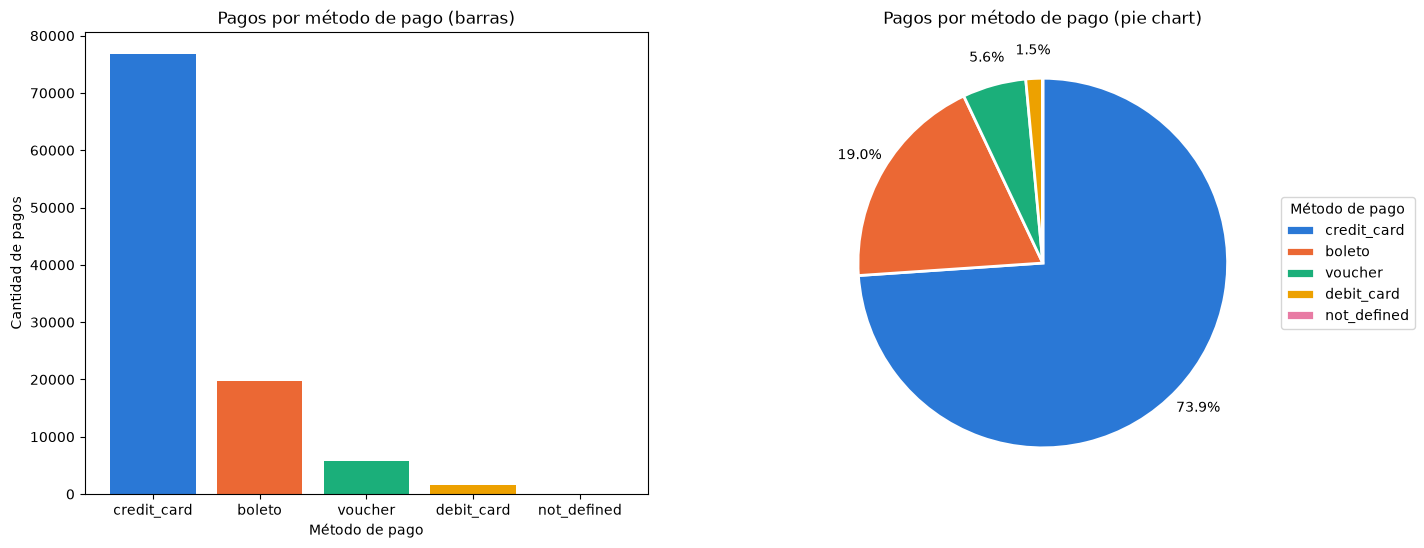

In [61]:
fig, (ax_barras, ax_pie) = plt.subplots(1, 2, figsize=(16, 6))

ax_barras.bar(cantidad_pagos_por_metodo.index, cantidad_pagos_por_metodo.values, color=colores_metodos_pago)
ax_barras.set_title("Pagos por método de pago (barras)")
ax_barras.set_xlabel("Método de pago")
ax_barras.set_ylabel("Cantidad de pagos")

ax_pie.pie(
    cantidad_pagos_por_metodo.values,
    autopct=mostrar_porcentaje_si_es_visible,
    pctdistance=1.15,
    colors=colores_metodos_pago,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
ax_pie.legend(cantidad_pagos_por_metodo.index, title="Método de pago", loc="center left", bbox_to_anchor=(1, 0.5))
ax_pie.set_title("Pagos por método de pago (pie chart)")

plt.show()

---
## Reto de personalización



- Un color diferente para cada barra (los mismos colores del ejercicio 8).
- La cantidad escrita encima de cada barra con `ax.bar_label`.
- Título más grande y en negritas.
- Una cuadrícula suave en el eje Y y sin los bordes de arriba y de la derecha.

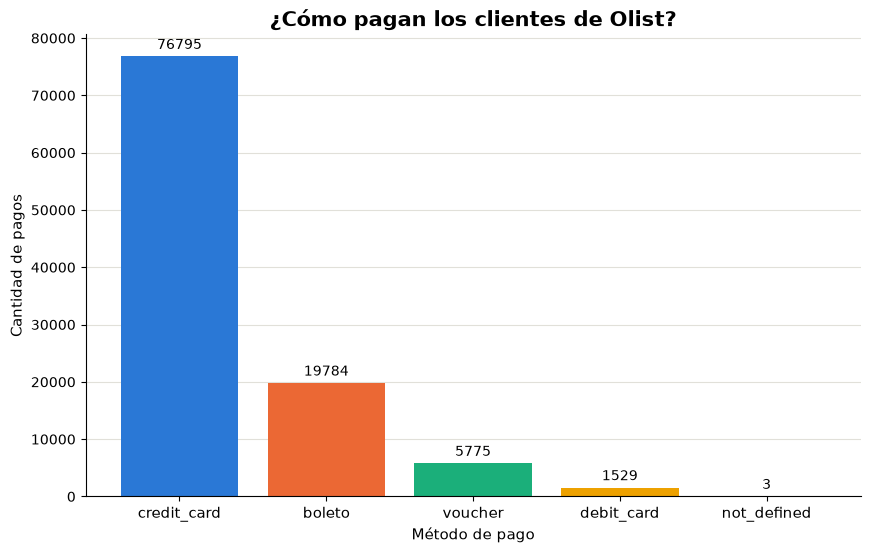

In [62]:
fig, ax = plt.subplots(figsize=(10, 6))

barras_metodos_pago = ax.bar(cantidad_pagos_por_metodo.index, cantidad_pagos_por_metodo.values, color=colores_metodos_pago)
ax.bar_label(barras_metodos_pago, padding=3)

ax.set_title("¿Cómo pagan los clientes de Olist?", fontsize=15, fontweight="bold")
ax.set_xlabel("Método de pago", fontsize=11)
ax.set_ylabel("Cantidad de pagos", fontsize=11)

ax.grid(axis="y", color="#e1e0d9")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(fontsize=11)

plt.show()